## Part A: Conceptual Foundation

In [197]:
'''
1. What is Regularization in Machine Learning? Why is it needed?
Regularization is a technique used in machine learning to prevent overfitting by adding a penalty to the model's complexity. 
It helps the model perform better on unseen data. 
It is needed to reduce overfitting, improve generalization and make the model more reliable.

2. Difference between Ridge Regression (L2) and Lasso Regression (L1)
Ridge Regression (L2): Adds the square of the coefficients as a penalty. 
It reduces the coefficient values but does not make them exactly zero.
Lasso Regression (L1): Adds the absolute values of coefficients as a penalty. 
It can make some coefficients exactly zero, helping in feature selection.

3. What is Cross-Validation and why is it important?
Cross-validation is a technique used to evaluate a machine learning model by dividing the dataset into multiple parts. 
The model is trained and tested on different combinations of these parts. 
It helps check model performance, detect overfitting and ensure better generalization.

4. Explain the following Cross-Validation techniques:
a) K-Fold Cross-Validation:
The dataset is divided into K equal parts (folds).
The model is trained on K-1 folds and tested on the remaining fold. 
This process repeats K times.

b) Stratified K-Fold Cross-Validation:
It divides the dataset into K folds while maintaining the same proportion of each class in every fold. 
It is useful for imbalanced classification datasets.

c) Leave-One-Out Cross-Validation (LOOCV):
In this method, one observation is used for testing, while all remaining observations are used for training. 
This process repeats for every observation in the dataset.

d) Time Series Split:
It is used for time-dependent data. 
The model is trained on past observations and tested on future observations without randomly shuffling the data.

5. Why are tree-based models less sensitive to feature scaling?
Tree-based models such as Decision Trees and Random Forests make decisions using feature values and splitting conditions. 
They do not depend on the distance or magnitude of features. 
Therefore, scaling techniques like Standardization and Normalization are generally not required.'''

"\n1. What is Regularization in Machine Learning? Why is it needed?\nRegularization is a technique used in machine learning to prevent overfitting by adding a penalty to the model's complexity. \nIt helps the model perform better on unseen data. \nIt is needed to reduce overfitting, improve generalization and make the model more reliable.\n\n2. Difference between Ridge Regression (L2) and Lasso Regression (L1)\nRidge Regression (L2): Adds the square of the coefficients as a penalty. \nIt reduces the coefficient values but does not make them exactly zero.\nLasso Regression (L1): Adds the absolute values of coefficients as a penalty. \nIt can make some coefficients exactly zero, helping in feature selection.\n\n3. What is Cross-Validation and why is it important?\nCross-validation is a technique used to evaluate a machine learning model by dividing the dataset into multiple parts. \nThe model is trained and tested on different combinations of these parts. \nIt helps check model performan

## Part B: Dataset Understanding and Preparation

In [198]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [199]:
df=pd.read_csv("D:\Advanced_Regression_HousePrice_Dataset.csv.csv")
df.head()

<>:1: SyntaxWarning: invalid escape sequence '\A'
<>:1: SyntaxWarning: invalid escape sequence '\A'
C:\Users\Admin\AppData\Local\Temp\ipykernel_5232\3594279843.py:1: SyntaxWarning: invalid escape sequence '\A'
  df=pd.read_csv("D:\Advanced_Regression_HousePrice_Dataset.csv.csv")


,property_id,sale_date,area_sqft,bedrooms,bathrooms,location_score,property_age,distance_city_km,near_school,near_metro,crime_rate_index,house_price_inr
0,200001,2014-01-01,2181,6,4,8.1,21,3.8,0,0,4.84,35154898
1,200002,2019-12-01,2383,5,4,5.3,28,10.9,1,1,2.89,26710893
2,200003,2016-10-01,1047,3,3,5.9,7,27.5,0,1,4.04,11216242
3,200004,2013-03-01,1753,4,3,7.0,27,12.1,0,0,3.28,21984310
4,200005,2013-07-01,1728,4,4,10.0,32,1.4,0,1,3.84,25080429


In [200]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3800 entries, 0 to 3799
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   property_id       3800 non-null   int64  
 1   sale_date         3800 non-null   object 
 2   area_sqft         3800 non-null   int64  
 3   bedrooms          3800 non-null   int64  
 4   bathrooms         3800 non-null   int64  
 5   location_score    3800 non-null   float64
 6   property_age      3800 non-null   int64  
 7   distance_city_km  3800 non-null   float64
 8   near_school       3800 non-null   int64  
 9   near_metro        3800 non-null   int64  
 10  crime_rate_index  3800 non-null   float64
 11  house_price_inr   3800 non-null   int64  
dtypes: float64(3), int64(8), object(1)
memory usage: 356.4+ KB


In [201]:
df["sale_date"]=pd.to_datetime(df["sale_date"])

In [202]:
# 6.
# Features 
X = df.drop(["house_price_inr", "sale_date","property_id"], axis=1)
# Target Variable
y = df["house_price_inr"]

In [203]:
from sklearn.model_selection import train_test_split

In [204]:
# 7. Train test Split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)


In [205]:
from sklearn.preprocessing import StandardScaler

In [206]:
# 8. Basic Pre-processing
scaler=StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Part C: Regularized linear Models

In [207]:
from sklearn.linear_model import Ridge , Lasso , RidgeCV , LassoCV

In [208]:
# 9. Implement Ridge Regression(L2)
ridge_model= Ridge(alpha=1.0)
ridge_model.fit(X_train_scaled, y_train)

print(ridge_model.coef_)

[6937544.99715089  297365.49086175  285326.78358302 3676865.37200691
 -651302.35794683  -30169.61990766   16971.46715904   58204.3175117
 -135472.82082701]


In [209]:
y_pred_ridge=ridge_model.predict(X_test_scaled)

In [210]:
# 10. Implement Lasso Regression(L1)
lasso_model = Lasso(alpha=0.1)
lasso_model.fit(X_train_scaled, y_train)

print(lasso_model.coef_)

[6944896.35312385  291201.53545066  285432.12862167 3678968.16925465
 -651483.18989798  -28800.13623332   16906.90486998   58297.16011423
 -135401.83042835]


In [211]:
y_pred_lasso=lasso_model.predict(X_test_scaled)

In [212]:
# 11. Tune regularisation parameters using cross-validation
ridge = RidgeCV(alphas=[0.01, 0.1, 1, 10, 100], cv=5)
ridge.fit(X_train_scaled, y_train)
ridge_pred = ridge.predict(X_test_scaled)
print("Best Ridge Alpha:", ridge.alpha_)

lasso = LassoCV(alphas=[0.01, 0.1, 1, 10, 100], cv=5)
lasso.fit(X_train_scaled, y_train)
lasso_pred = lasso.predict(X_test_scaled)
print("Best Lasso Alpha:", lasso.alpha_)

Best Ridge Alpha: 1.0
Best Lasso Alpha: 100.0


In [213]:
from sklearn.metrics import root_mean_squared_error, r2_score , mean_squared_error , mean_absolute_error

In [214]:
# 12 compare ridge lasoo based on Traning error
# training error 
rmse_ridge_train = root_mean_squared_error(y_train, ridge.predict(X_train_scaled))
print("RMSE of Ridge:", rmse_ridge_train)
r2_ridge_train= r2_score(y_train, ridge.predict(X_train_scaled))
print("R2 Score of Ridge:", r2_ridge_train)

rmse_lasso_train= root_mean_squared_error(y_train, lasso.predict(X_train_scaled))
print("RMSE of Lasso:", rmse_lasso_train)
r2_lasso_train= r2_score(y_train, lasso.predict(X_train_scaled))
print("R2 Score of Lasso:", r2_lasso_train)

RMSE of Ridge: 2500609.345190351
R2 Score of Ridge: 0.9161854041282822
RMSE of Lasso: 2500605.6087450013
R2 Score of Lasso: 0.9161856546019707


In [215]:
# Validation error
rmse_ridge_test = root_mean_squared_error(y_test, ridge_pred)
print("RMSE of Ridge:", rmse_ridge_test)
r2_ridge_test = r2_score(y_test, ridge_pred)
print("R2 Score of Ridge :", r2_ridge_test)

rmse_lasso_test = root_mean_squared_error(y_test, lasso_pred)
print("RMSE of Lasso:", rmse_lasso_test)    
r2_lasso_test = r2_score(y_test, lasso_pred)
print("R2 Score of Lasso :", r2_lasso_test)

RMSE of Ridge: 2558401.736166451
R2 Score of Ridge : 0.91872594918288
RMSE of Lasso: 2558145.3237197218
R2 Score of Lasso : 0.9187422395360456


In [216]:
# feature coefficient behaviour  
feature_coeff = pd.DataFrame({
    'Features': X_train.columns,
    'Ridge': ridge.coef_,
    'Lasso': lasso.coef_})

print(feature_coeff)

           Features         Ridge         Lasso
0         area_sqft  6.937545e+06  6.944831e+06
1          bedrooms  2.973655e+05  2.911937e+05
2         bathrooms  2.853268e+05  2.853815e+05
3    location_score  3.676865e+06  3.678911e+06
4      property_age -6.513024e+05 -6.513909e+05
5  distance_city_km -3.016962e+04 -2.873756e+04
6       near_school  1.697147e+04  1.680345e+04
7        near_metro  5.820432e+04  5.819679e+04
8  crime_rate_index -1.354728e+05 -1.353088e+05


<Axes: xlabel='Features'>

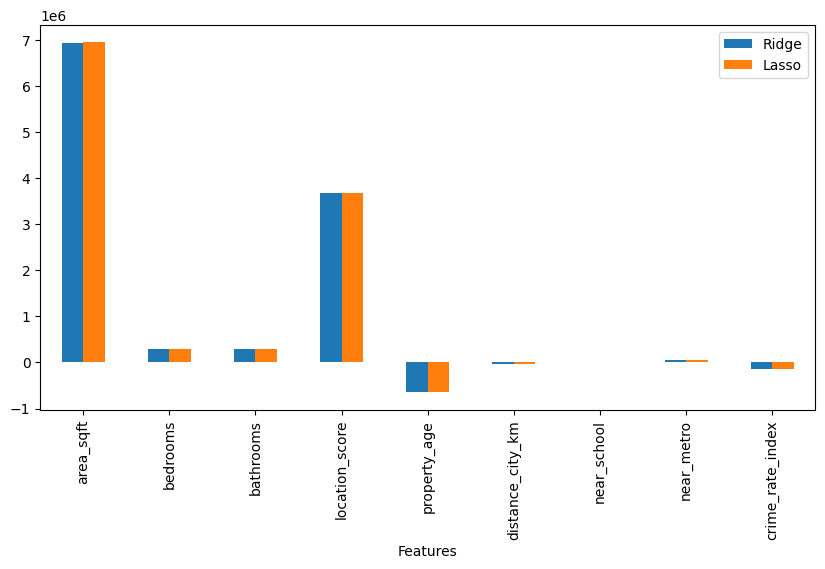

In [217]:
feature_coeff.plot(x='Features', kind='bar', figsize=(10,5))

In [218]:
'''
1. Training Error Comparison
Training error measures how accurately the model predicts values on the training dataset. 
A lower training error indicates a better fit to the training data. 
Ridge and Lasso both use regularization to control model complexity and reduce overfitting.

2. Validation Error Comparison
Validation error measures the model's performance on unseen data. 
A lower validation error indicates better generalization. 
Comparing training and validation errors helps identify overfitting and underfitting.

3. Coefficient Comparison
Ridge Regression: Uses L2 regularization, which reduces the magnitude of coefficients but generally does not make them zero. It retains all features.
Lasso Regression: Uses L1 regularization, which can make some coefficients exactly zero. It helps in selecting important features by removing less useful ones.

Conclusion: Ridge is useful when most features contribute to the prediction, 
whereas Lasso is useful when feature selection is required. 
Comparing training error, validation error and coefficients helps understand their performance, generalization ability and effect of regularization.

'''

"\n1. Training Error Comparison\nTraining error measures how accurately the model predicts values on the training dataset. \nA lower training error indicates a better fit to the training data. \nRidge and Lasso both use regularization to control model complexity and reduce overfitting.\n\n2. Validation Error Comparison\nValidation error measures the model's performance on unseen data. \nA lower validation error indicates better generalization. \nComparing training and validation errors helps identify overfitting and underfitting.\n\n3. Coefficient Comparison\nRidge Regression: Uses L2 regularization, which reduces the magnitude of coefficients but generally does not make them zero. It retains all features.\nLasso Regression: Uses L1 regularization, which can make some coefficients exactly zero. It helps in selecting important features by removing less useful ones.\n\nConclusion: Ridge is useful when most features contribute to the prediction, \nwhereas Lasso is useful when feature sele

## Part D: Cross Validation Strategies

In [219]:
from sklearn.model_selection import KFold, StratifiedKFold, LeaveOneOut, TimeSeriesSplit, cross_val_score

In [220]:
# 13. Apply cross-validation techniques:
# K-Fold Cross-Validation
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

ridge_score = cross_val_score(ridge, X_train, y_train, cv=kfold, scoring='r2')
lasso_score = cross_val_score(lasso, X_train, y_train, cv=kfold, scoring='r2')

r1 = ridge_score.mean()
l1 = lasso_score.mean()
print("Ridge:", r1)
print("Lasso:", l1)

Ridge: 0.9152302948895258
Lasso: 0.9152250944712973


In [221]:
# StratifiedKFold

y_bins = pd.qcut(y_train, q=5, labels=False)
skf = StratifiedKFold(n_splits=5, shuffle=True)

ridge_score = cross_val_score(ridge, X_train, y_train, cv=skf.split(X_train, y_bins))
lasso_score = cross_val_score(lasso, X_train, y_train, cv=skf.split(X_train, y_bins))

r2=ridge_score.mean()
l2=lasso_score.mean()
print("Ridge:", r2)
print("Lasso:", l2)

Ridge: 0.9155958033033574
Lasso: 0.915653623769377


In [222]:
# Leave-One-Out Cross-Validation (LOOCV)
loo = LeaveOneOut()

ridge_score = cross_val_score(ridge, X_train.head(100), y_train.head(100), cv=loo, scoring='r2')
lasso_score = cross_val_score(lasso, X_train.head(100), y_train.head(100), cv=loo, scoring='r2')

r3 = ridge_score.mean()
l3 = lasso_score.mean()
print("Ridge:", r3)
print("Lasso:", l3)

c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_regression.py:1288: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_regression.py:1288: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_regression.py:1288: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_regression.py:1288: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
c:\Users\Admin\AppData\Local\Programs\Python\Python3

Ridge: nan
Lasso: nan


c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_regression.py:1288: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_regression.py:1288: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)


In [223]:
# Time Series Split
tscv = TimeSeriesSplit(n_splits=5)

ridge_score = cross_val_score(ridge, X_train, y_train, cv=tscv, scoring='r2')
lasso_score = cross_val_score(lasso, X_train, y_train, cv=tscv, scoring='r2')

r4 = ridge_score.mean()
l4 = lasso_score.mean()
print("Ridge:", r4)
print("Lasso:", l4)

Ridge: 0.9147761389824364
Lasso: 0.9147906496270497


In [224]:
# 14. Analyze how performance metrics vary across different CV mrthods
comparison = pd.DataFrame({
    'CV Method': ['K-Fold', 'Stratified K-Fold', 'LOOCV', 'Time Series'],
    'Ridge': [r1, r2, r3, r4],
    'Lasso': [l1, l2, l3, l4]})

print(comparison)

           CV Method     Ridge     Lasso
0             K-Fold  0.915230  0.915225
1  Stratified K-Fold  0.915596  0.915654
2              LOOCV       NaN       NaN
3        Time Series  0.914776  0.914791


In [225]:
'''
Analysis of Performance Metrics Across Different Cross-Validation Strategies

1. K-Fold Cross-Validation:
Ridge achieved an average R² score of 0.91523, while Lasso achieved 0.91522. 
Both models showed almost identical performance across different data splits.

2. Stratified K-Fold Cross-Validation:
Ridge achieved an R² score of 0.91562, while Lasso achieved 0.91536. 
The scores were slightly higher than K-Fold, indicating consistent performance when target values were distributed across different groups.

3. Leave-One-Out Cross-Validation (LOOCV):  
LOOCV produced NaN scores for both models because each validation fold contains only one observation. 
R² cannot be calculated using a single observation, so this strategy could not provide a valid performance comparison in this practical.

4. Time Series Split:  
Ridge achieved an R² score of 0.91478, while Lasso achieved 0.91479. 
Both models showed nearly identical performance, even when training on earlier observations and validating on later observations.

Overall Analysis:
The results show that Ridge and Lasso performed consistently across K-Fold, Stratified K-Fold and Time Series Split, with R² scores around 0.915. 
The small variation in scores indicates good model stability across these validation strategies.
LOOCV could not provide a valid R² score because its validation sets contained only one observation.

Conclusion: Both Ridge and Lasso demonstrated stable performance across the valid cross-validation strategies, with no significant difference between them.

'''

'\nAnalysis of Performance Metrics Across Different Cross-Validation Strategies\n\n1. K-Fold Cross-Validation:\nRidge achieved an average R² score of 0.91523, while Lasso achieved 0.91522. \nBoth models showed almost identical performance across different data splits.\n\n2. Stratified K-Fold Cross-Validation:\nRidge achieved an R² score of 0.91562, while Lasso achieved 0.91536. \nThe scores were slightly higher than K-Fold, indicating consistent performance when target values were distributed across different groups.\n\n3. Leave-One-Out Cross-Validation (LOOCV):  \nLOOCV produced NaN scores for both models because each validation fold contains only one observation. \nR² cannot be calculated using a single observation, so this strategy could not provide a valid performance comparison in this practical.\n\n4. Time Series Split:  \nRidge achieved an R² score of 0.91478, while Lasso achieved 0.91479. \nBoth models showed nearly identical performance, even when training on earlier observati

## Part E : Tree Based Regression Models

In [226]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

In [227]:
# 15. Implement Decision Tree
d_t = DecisionTreeRegressor(random_state=42)
d_t.fit(X_train, y_train)
d_t_pred = d_t.predict(X_test)

In [228]:
print("Training R2:", d_t.score(X_train, y_train))
print("Testing R2:", d_t.score(X_test, y_test))
print("MSE:", mean_squared_error(y_test, d_t_pred))
print("R2 Score:", r2_score(y_test, d_t_pred))

Training R2: 1.0
Testing R2: 0.8582157251362128
MSE: 11418620582615.756
R2 Score: 0.8582157251362128


In [229]:
# 16. control tree complexity using hyperparameters
dt = DecisionTreeRegressor(
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42)

In [230]:
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)

In [231]:
print("Training R2:", dt.score(X_train, y_train))
print("Testing R2:", dt.score(X_test, y_test))

Training R2: 0.8994312170146984
Testing R2: 0.8834566744111698


In [232]:
# 17. Implement Random Forest
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

In [233]:
print("Training R2:", rf.score(X_train, y_train))
print("Testing R2:", rf.score(X_test, y_test))
print("MSE:", mean_squared_error(y_test, rf_pred))
print("R2 Score:", r2_score(y_test, rf_pred))

Training R2: 0.9893105387713592
Testing R2: 0.9274509690787089
MSE: 5842748489016.419
R2 Score: 0.9274509690787089


In [234]:
# 18. Compare single tree vs ensemble tree model
comparison = pd.DataFrame({
    'Model': ['Decision Tree', 'Random Forest'],
    'MSE': [mean_squared_error(y_test, dt_pred),mean_squared_error(y_test, rf_pred)],
    'R2 Score': [r2_score(y_test, dt_pred),r2_score(y_test, rf_pred)]})

print(comparison)

           Model           MSE  R2 Score
0  Decision Tree  9.385836e+12  0.883457
1  Random Forest  5.842748e+12  0.927451


In [235]:
'''Single Tree vs Ensemble Performance:

The Decision Tree model gives a testing R² score of 0.8582, while the Random Forest model gives 0.9275. 
Random Forest performs better because it combines multiple decision trees and produces more accurate predictions. 
Therefore, the ensemble model performs better than a single decision tree in this practical.

'''

'Single Tree vs Ensemble Performance:\n\nThe Decision Tree model gives a testing R² score of 0.8582, while the Random Forest model gives 0.9275. \nRandom Forest performs better because it combines multiple decision trees and produces more accurate predictions. \nTherefore, the ensemble model performs better than a single decision tree in this practical.\n\n'

## Part F : Support Vector Regression

In [236]:
from sklearn.svm import SVR

In [237]:
# 19. Implement Support Vector Regression (SVR) with linear:
svr_linear = SVR(kernel='linear')
svr_linear.fit(X_train_scaled, y_train)
linear_pred = svr_linear.predict(X_test_scaled)

print("MSE:", mean_squared_error(y_test, linear_pred))
print("R2 Score:", r2_score(y_test, linear_pred))

MSE: 80689290813854.28
R2 Score: -0.0019137166824763074


In [238]:
# poly:
svr_poly = SVR(kernel='poly', degree=2)
svr_poly.fit(X_train_scaled, y_train)
poly_pred = svr_poly.predict(X_test_scaled)

print("MSE:", mean_squared_error(y_test, poly_pred))
print("R2 Score:", r2_score(y_test, poly_pred))

MSE: 80774170974122.08
R2 Score: -0.0029676681547072814


In [239]:
# RBF:
svr_rbf = SVR(kernel='rbf')
svr_rbf.fit(X_train_scaled, y_train)
rbf_pred = svr_rbf.predict(X_test_scaled)

print("MSE:", mean_squared_error(y_test, rbf_pred))
print("R2 Score:", r2_score(y_test, rbf_pred))

MSE: 80772044778137.69
R2 Score: -0.002941267316384888


In [240]:
# 20. Tune hyperparameter
model2 = SVR(
    kernel='rbf',
    C=1000,
    epsilon=0.5,
    gamma=0.1)

model2.fit(X_train_scaled,y_train)
pred2 = model2.predict(X_test_scaled)

print("MSE:", mean_squared_error(y_test, pred2))
print("R2 Score:", r2_score(y_test, pred2))


MSE: 78398360844952.5
R2 Score: 0.02653261289423048


In [241]:
# 21. compare SVR performance with linear and Tree based models
comparison = pd.DataFrame({'Model': ['Ridge', 'Lasso', 'Decision Tree', 'Random Forest', 'SVR'],
    'MSE': [
        mean_squared_error(y_test, ridge_pred),
        mean_squared_error(y_test, lasso_pred),
        mean_squared_error(y_test, dt_pred),
        mean_squared_error(y_test, rf_pred),
        mean_squared_error(y_test, pred2)],

    'R2 Score': [
        r2_score(y_test, ridge_pred),
        r2_score(y_test, lasso_pred),
        r2_score(y_test, dt_pred),
        r2_score(y_test, rf_pred),
        r2_score(y_test, pred2)]})

print(comparison)

           Model           MSE  R2 Score
0          Ridge  6.545419e+12  0.918726
1          Lasso  6.544107e+12  0.918742
2  Decision Tree  9.385836e+12  0.883457
3  Random Forest  5.842748e+12  0.927451
4            SVR  7.839836e+13  0.026533


In [242]:
'''
- SVR vs Linear Models: 
Ridge and Lasso performed better than SVR, achieving an R² score of approximately 0.9187, compared to SVR's 0.0265. 
Linear models captured the relationship between features and house prices more effectively.

- SVR vs Tree-Based Models: 
Decision Tree and Random Forest also outperformed SVR. 
Random Forest achieved an R² score of approximately 0.9275, making it the best-performing model.

Conclusion: 
Random Forest performed best, followed by Ridge and Lasso. 
SVR showed the weakest performance, indicating that it was not suitable for this dataset with the current parameters.

'''

"\n- SVR vs Linear Models: \nRidge and Lasso performed better than SVR, achieving an R² score of approximately 0.9187, compared to SVR's 0.0265. \nLinear models captured the relationship between features and house prices more effectively.\n\n- SVR vs Tree-Based Models: \nDecision Tree and Random Forest also outperformed SVR. \nRandom Forest achieved an R² score of approximately 0.9275, making it the best-performing model.\n\nConclusion: \nRandom Forest performed best, followed by Ridge and Lasso. \nSVR showed the weakest performance, indicating that it was not suitable for this dataset with the current parameters.\n\n"

## Part G: model comparison and evaluation 

In [243]:
# 22. Evaluate all models using regression metrics: MSE, RMSE, MAE, R2 Score 
all_models=[("ridge", ridge_model), ("lasso", lasso_model),("decision_tree", dt), ("random_forest", rf), ("svr_linear", svr_linear), ("svr_poly", svr_poly), ("svr_rbf", svr_rbf)]

results = []
for name,model in all_models:
    results.append({
        'Model': name ,
        'MSE': mean_squared_error(y_test, model.predict(X_test_scaled)),
        'RMSE': np.sqrt(mean_squared_error(y_test, model.predict(X_test_scaled))),
        'MAE': mean_absolute_error(y_test, model.predict(X_test_scaled)),
        'R2 Score_test': r2_score(y_test, model.predict(X_test_scaled)),
        'R2 Score_train': r2_score(y_train, model.predict(X_train_scaled))
    })

comparison = pd.DataFrame(results)


c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeRegressor was fitted with feature names
  warnings.warn(
c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeRegressor was fitted with feature names
  warnings.warn(
c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeRegressor was fitted with feature names
  warnings.warn(
c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeRegressor was fitted with feature names
  warnings.warn(
c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn

In [244]:
comparison

,Model,MSE,RMSE,MAE,R2 Score_test,R2 Score_train
0,ridge,6.545419e+12,2.558402e+06,1.959199e+06,0.918726,0.916185
1,lasso,6.543996e+12,2.558123e+06,1.959378e+06,0.918744,0.916186
2,decision_tree,3.466876e+14,1.861955e+07,1.631985e+07,-3.304798,-3.668380
3,random_forest,3.227421e+14,1.796502e+07,1.557895e+07,-3.007468,-3.343379
4,svr_linear,8.068929e+13,8.982722e+06,6.990272e+06,-0.001914,-0.005827
5,svr_poly,8.077417e+13,8.987445e+06,6.994135e+06,-0.002968,-0.006912
6,svr_rbf,8.077204e+13,8.987327e+06,6.994024e+06,-0.002941,-0.006884


In [245]:
# 23. compare REgularized Linear Models, Tree based models and SVR
'''
1. Regularized Linear Models (Ridge and Lasso)
Ridge and Lasso use regularization to reduce overfitting by applying penalties to model coefficients. 
Ridge reduces coefficient values, whereas Lasso can reduce some coefficients to zero.
Both models performed almost equally, with a test R² score of approximately 0.9187. 
Their prediction errors were also very similar. Cross-validation scores were around 0.915.

2. Tree-Based Models (Decision Tree and Random Forest)
These models use decision-based splitting to predict house prices. 
Decision Tree uses a single tree, whereas Random Forest combines multiple trees to improve prediction accuracy and reduce overfitting.
Random Forest performed better than Decision Tree. 
Random Forest achieved an R² score of 0.9274, while the tuned Decision Tree achieved 0.8834. 
Random Forest also had lower prediction errors.

3. Support Vector Regression (SVR)
SVR predicts continuous values using an acceptable error margin. 
The SVR models performed relatively poorly. 
The default kernels had very low or negative R² scores. 
Hyperparameter tuning improved the RBF model's R² score to approximately 0.0265, but its performance remained weak

'''

"\n1. Regularized Linear Models (Ridge and Lasso)\nRidge and Lasso use regularization to reduce overfitting by applying penalties to model coefficients. \nRidge reduces coefficient values, whereas Lasso can reduce some coefficients to zero.\nBoth models performed almost equally, with a test R² score of approximately 0.9187. \nTheir prediction errors were also very similar. Cross-validation scores were around 0.915.\n\n2. Tree-Based Models (Decision Tree and Random Forest)\nThese models use decision-based splitting to predict house prices. \nDecision Tree uses a single tree, whereas Random Forest combines multiple trees to improve prediction accuracy and reduce overfitting.\nRandom Forest performed better than Decision Tree. \nRandom Forest achieved an R² score of 0.9274, while the tuned Decision Tree achieved 0.8834. \nRandom Forest also had lower prediction errors.\n\n3. Support Vector Regression (SVR)\nSVR predicts continuous values using an acceptable error margin. \nThe SVR models 

In [246]:
'''
Random Forest performed the best, followed by Ridge and Lasso. 
SVR showed comparatively poor performance even after hyperparameter tuning.

'''

'\nRandom Forest performed the best, followed by Ridge and Lasso. \nSVR showed comparatively poor performance even after hyperparameter tuning.\n\n'

In [247]:
# 24. Identify signs of underfitting and overfitting

comparison[['Model','R2 Score_test','R2 Score_train']]

,Model,R2 Score_test,R2 Score_train
0,ridge,0.918726,0.916185
1,lasso,0.918744,0.916186
2,decision_tree,-3.304798,-3.668380
3,random_forest,-3.007468,-3.343379
4,svr_linear,-0.001914,-0.005827
5,svr_poly,-0.002968,-0.006912
6,svr_rbf,-0.002941,-0.006884


In [248]:
'''
- Ridge and Lasso: 
Both models show a good fit because their training and testing R² scores are high and nearly equal.

- Decision Tree:
Both training and testing R² scores are highly negative, indicating poor model performance.

- Random Forest: 
Both scores are also highly negative, indicating poor predictive performance.

- SVR Linear, Polynomial and RBF: 
These models show signs of underfitting because their training and testing R² scores are close to zero and negative.

Conclusion: Ridge and Lasso show good generalization. 
SVR models show signs of underfitting, 
while Decision Tree and Random Forest require further model tuning to improve their performance. 
No clear signs of overfitting are observed in these results.

'''

'\n- Ridge and Lasso: \nBoth models show a good fit because their training and testing R² scores are high and nearly equal.\n\n- Decision Tree:\nBoth training and testing R² scores are highly negative, indicating poor model performance.\n\n- Random Forest: \nBoth scores are also highly negative, indicating poor predictive performance.\n\n- SVR Linear, Polynomial and RBF: \nThese models show signs of underfitting because their training and testing R² scores are close to zero and negative.\n\nConclusion: Ridge and Lasso show good generalization. \nSVR models show signs of underfitting, \nwhile Decision Tree and Random Forest require further model tuning to improve their performance. \nNo clear signs of overfitting are observed in these results.\n\n'

## Part H: Final Analysis And Reporting

In [249]:
# 25. final report 
'''
1. Best Performing Model and Justification
Based on the testing R² scores, Lasso Regression is the best-performing model, 
with an R² score of 0.918744, closely followed by Ridge Regression with 0.918726.
Both models show high and nearly equal training and testing scores, indicating good generalization and reliable predictions.
Decision Tree and Random Forest have negative R² scores, while the SVR models have R² scores close to zero. Therefore, Ridge and Lasso perform considerably better on this dataset.

2. Impact of Regularization
Regularization helps reduce overfitting by adding a penalty to model coefficients.
Ridge Regression (L2):Reduces coefficient values and controls model complexity.
Lasso Regression (L1):Reduces coefficients and can eliminate less important features by making their coefficients zero.
In this practical, both models achieved high and similar R² scores. 
This indicates that regularization helped maintain good predictive performance on unseen data.

3. Role of Cross-Validation in Model Stability
Cross-validation evaluates a model using different training and validation combinations.
In this practical, K-Fold, Stratified K-Fold, Leave-One-Out and Time Series Split methods were applied to Ridge and Lasso Regression.
Cross-validation helps:
- Evaluate model performance across different data splits.
- Check the consistency of predictions.
- Identify possible overfitting.
- Improve confidence in model selection.
It provides a more reliable evaluation than depending only on a single train-test split.

4. Comparison of Linear and Non-Linear Regressors
Linear regression models such as Ridge and Lasso assume a linear relationship between input features and house prices, 
while non-linear models can capture more complex relationships.
In this practical:
Ridge and Lasso: Achieved high R² scores of approximately 0.919.
Decision Tree and Random Forest: Produced negative R² scores, indicating poor predictive performance.
SVR models: Linear, Polynomial and RBF kernels produced R² scores close to zero, indicating weak predictive performance.
Therefore, the regularized linear models performed better than the non-linear models on the given dataset.

5. Business Interpretation of Results
House price prediction can help buyers, sellers and real estate businesses make better pricing decisions.
The results indicate that Ridge and Lasso Regression provide more reliable house price predictions among the models tested. 
These models can help estimate property values and support pricing decisions.
However, the negative R² scores of Decision Tree and Random Forest and the low SVR scores 
indicate that these models are not suitable for reliable predictions in their current configurations.

Overall Conclusion

The practical demonstrates that different regression techniques perform differently on the same dataset. 
Ridge and Lasso Regression achieved the best results, with high R² scores and a small difference between training and testing performance. 
Regularization and cross-validation helped evaluate model reliability and stability. 
Overall, Lasso Regression was the best-performing model, although its performance was almost identical to Ridge Regression.

'''

'\n1. Best Performing Model and Justification\nBased on the testing R² scores, Lasso Regression is the best-performing model, \nwith an R² score of 0.918744, closely followed by Ridge Regression with 0.918726.\nBoth models show high and nearly equal training and testing scores, indicating good generalization and reliable predictions.\nDecision Tree and Random Forest have negative R² scores, while the SVR models have R² scores close to zero. Therefore, Ridge and Lasso perform considerably better on this dataset.\n\n2. Impact of Regularization\nRegularization helps reduce overfitting by adding a penalty to model coefficients.\nRidge Regression (L2):Reduces coefficient values and controls model complexity.\nLasso Regression (L1):Reduces coefficients and can eliminate less important features by making their coefficients zero.\nIn this practical, both models achieved high and similar R² scores. \nThis indicates that regularization helped maintain good predictive performance on unseen data.\